# INT315 — Hospital Readmission Prediction with PySpark


This notebook is designed around the INT315 requirement to use PySpark and a Decision Tree classifier. It adds safer preprocessing, meaningful visualizations, threshold tuning, model metrics, and export files for Power BI and the final report.

**Dataset:** UCI Diabetes 130-US Hospitals for Years 1999–2008  
**Target:** readmission within 30 days (`readmitted == '<30'`)  
**Important:** this is an encounter-level dataset. A random row split can put encounters from the same patient in both train and test sets; we report this limitation and do not claim clinical deployment readiness.

## 1. Install and import libraries


In [4]:
%pip -q install pyspark

In [5]:
import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

plt.rcParams["figure.figsize"] = (9, 5)

spark = SparkSession.builder.appName("INT315_Hospital_Readmission").config(
    "spark.sql.shuffle.partitions", "8"
).getOrCreate()

print("Spark version:", spark.version)

Spark version: 4.0.4


## 2. Download the authentic UCI dataset

The notebook downloads the original UCI ZIP.

In [6]:
DATA_DIR = "/content/diabetes_readmission_data"
os.makedirs(DATA_DIR, exist_ok=True)
ZIP_PATH = os.path.join(DATA_DIR, "diabetes.zip")
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

if not os.path.exists(os.path.join(DATA_DIR, "diabetic_data.csv")):
    try:
        urllib.request.urlretrieve(UCI_ZIP_URL, ZIP_PATH)
        with zipfile.ZipFile(ZIP_PATH, "r") as zf:
            zf.extractall(DATA_DIR)
    except Exception as e:
        print("Automatic download failed:", repr(e))
        print("Download the ZIP from https://archive.ics.uci.edu/dataset/296/diabetes+130-us-hospitals+for-years+1999-2008")
        print("Upload it to Colab, set ZIP_PATH to the uploaded ZIP path, then rerun this cell.")
        raise

csv_path = os.path.join(DATA_DIR, "diabetic_data.csv")
if not os.path.exists(csv_path):
    candidates = []
    for root, _, files in os.walk(DATA_DIR):
        candidates += [os.path.join(root, f) for f in files if f.lower() == "diabetic_data.csv"]
    if candidates:
        csv_path = candidates[0]
    else:
        raise FileNotFoundError("Could not find diabetic_data.csv in the extracted dataset.")

print("Dataset file:", csv_path)

Dataset file: /content/diabetes_readmission_data/diabetic_data.csv


## 3. Load and inspect the data

In [7]:
raw_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .option("quote", '"')
    .option("escape", '"')
    .csv(csv_path)
)
print("Rows:", raw_df.count())
print("Columns:", len(raw_df.columns))
raw_df.printSchema()
raw_df.show(5, truncate=False)

Rows: 101766
Columns: 50
root
 |-- encounter_id: string (nullable = true)
 |-- patient_nbr: string (nullable = true)
 |-- race: string (nullable = true)
 |-- gender: string (nullable = true)
 |-- age: string (nullable = true)
 |-- weight: string (nullable = true)
 |-- admission_type_id: string (nullable = true)
 |-- discharge_disposition_id: string (nullable = true)
 |-- admission_source_id: string (nullable = true)
 |-- time_in_hospital: string (nullable = true)
 |-- payer_code: string (nullable = true)
 |-- medical_specialty: string (nullable = true)
 |-- num_lab_procedures: string (nullable = true)
 |-- num_procedures: string (nullable = true)
 |-- num_medications: string (nullable = true)
 |-- number_outpatient: string (nullable = true)
 |-- number_emergency: string (nullable = true)
 |-- number_inpatient: string (nullable = true)
 |-- diag_1: string (nullable = true)
 |-- diag_2: string (nullable = true)
 |-- diag_3: string (nullable = true)
 |-- number_diagnoses: string (nullable

## 4. Inspect original target labels and missing values

In this dataset, `<30` means readmitted within 30 days, `>30` means readmitted after 30 days, and `NO` means no recorded readmission. Our binary target marks only `<30` as 1.

In [8]:
raw_df.groupBy("readmitted").count().orderBy(F.desc("count")).show()

+----------+-----+
|readmitted|count|
+----------+-----+
|        NO|54864|
|       >30|35545|
|       <30|11357|
+----------+-----+



,Column,Missing_or_unknown_count,Percent_of_rows
1,weight,98569,96.86
3,medical_specialty,49949,49.08
2,payer_code,40256,39.56
0,race,2273,2.23
6,diag_3,1423,1.40
5,diag_2,358,0.35
4,diag_1,21,0.02


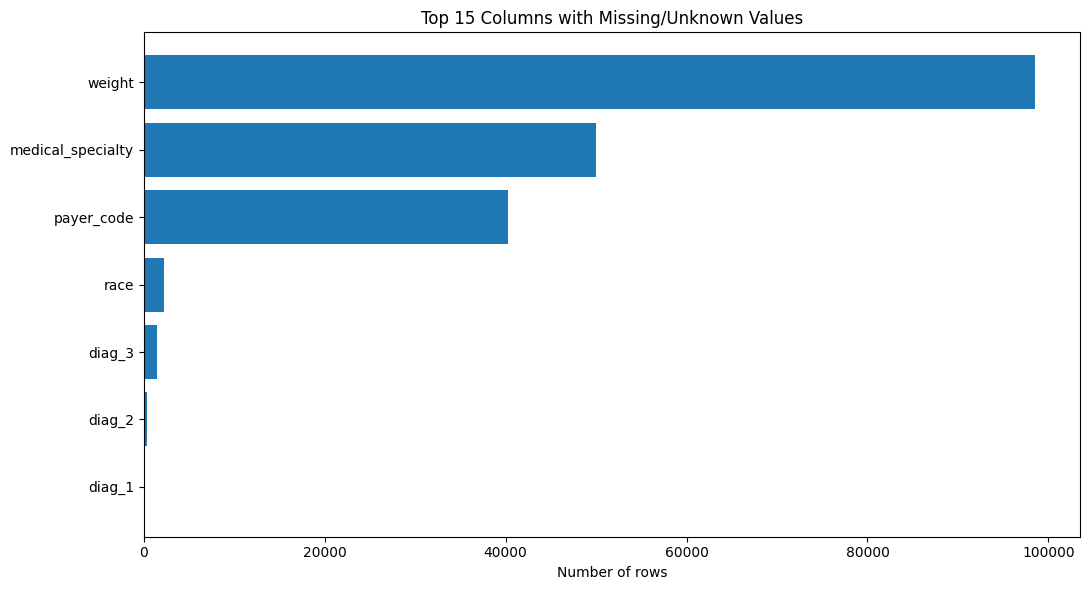

In [9]:
# Count missing or unknown values in each column.
row_count = raw_df.count()
missing_rows = []

for column_name in raw_df.columns:
    missing_count = raw_df.filter(
        F.col(column_name).isNull()
        | (F.trim(F.col(column_name)) == "")
        | (F.col(column_name) == "?")
    ).count()

    if missing_count > 0:
        percentage = round((missing_count / row_count) * 100, 2)
        missing_rows.append((column_name, missing_count, percentage))

# Convert the results into a Pandas DataFrame for display and plotting.
missing_pd = pd.DataFrame(
    missing_rows,
    columns=["Column", "Missing_or_unknown_count", "Percent_of_rows"]
)
missing_pd = missing_pd.sort_values(
    "Missing_or_unknown_count", ascending=False
)

display(missing_pd.head(20))

plt.figure(figsize=(11, 6))
plot_missing = missing_pd.head(15).sort_values("Missing_or_unknown_count")
plt.barh(plot_missing["Column"], plot_missing["Missing_or_unknown_count"])
plt.title("Top 15 Columns with Missing/Unknown Values")
plt.xlabel("Number of rows")
plt.tight_layout()
plt.show()

## 5. Clean data and define the target

We keep `medical_specialty` so we can analyze it later. It represents physician specialty, **not a confirmed hospital department**. We drop patient/encounter identifiers from model features. `weight` is omitted because it is missing for most encounters.

In [10]:
from pyspark.sql import functions as F
# Step 1: Check missing values before cleaning
required_fields = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]
print("Missing values BEFORE cleaning:")

for column_name in required_fields:
    missing_count = raw_df.filter(
        F.col(column_name).isNull() |
        (F.trim(F.col(column_name)) == "") |
        (F.trim(F.col(column_name)) == "?")
    ).count()

    print(f"{column_name}: {missing_count}")

# Step 2: Convert '?' and blank strings to null
clean_df = raw_df

for column_name in clean_df.columns:
    clean_df = clean_df.withColumn(
        column_name,
        F.when(
            F.col(column_name).isNull() |
            (F.trim(F.col(column_name)) == "") |
            (F.trim(F.col(column_name)) == "?"),
            F.lit(None).cast("string")
        ).otherwise(F.trim(F.col(column_name)))
    )

# Step 3: Explicitly replace missing admission/discharge codes
# with "Unknown"
for column_name in required_fields:
    clean_df = clean_df.withColumn(
        column_name,
        F.coalesce(F.col(column_name), F.lit("Unknown"))
    )

# Step 4: Create the 30-day readmission target
clean_df = clean_df.withColumn(
    "readmitted_30_days",
    F.when(F.col("readmitted") == "<30", 1.0).otherwise(0.0)
)

# Step 5: Verify the required fields after cleaning
print("\nMissing values AFTER cleaning:")

for column_name in required_fields:
    remaining = clean_df.filter(
        F.col(column_name).isNull() |
        (F.trim(F.col(column_name)) == "")
    ).count()

    print(f"{column_name}: {remaining}")

print("\nTarget distribution:")
clean_df.groupBy("readmitted_30_days").count().show()

print("Total rows:", clean_df.count())


Missing values BEFORE cleaning:
admission_type_id: 0
discharge_disposition_id: 0
admission_source_id: 0

Missing values AFTER cleaning:
admission_type_id: 0
discharge_disposition_id: 0
admission_source_id: 0

Target distribution:
+------------------+-----+
|readmitted_30_days|count|
+------------------+-----+
|               1.0|11357|
|               0.0|90409|
+------------------+-----+

Total rows: 101766


## 6. Exploratory graphs

The aggregations are performed in Spark; only the small summary tables are collected into Pandas for plotting. This avoids collecting the full patient-level dataset into local memory.

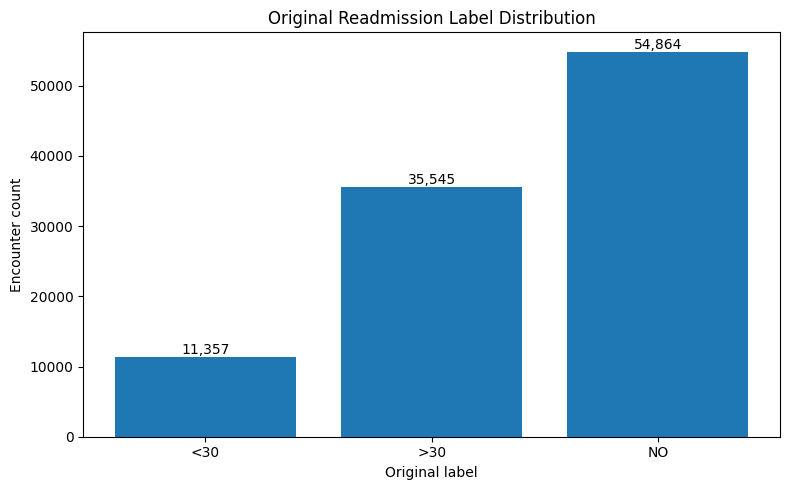

In [11]:
target_counts = (
    clean_df.groupBy("readmitted")
    .count().orderBy("readmitted")
    .toPandas()
)
plt.figure(figsize=(8, 5))
bars = plt.bar(target_counts["readmitted"].astype(str), target_counts["count"])
plt.title("Original Readmission Label Distribution")
plt.xlabel("Original label")
plt.ylabel("Encounter count")
for b in bars:
    plt.text(b.get_x()+b.get_width()/2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

,age,total_encounters,readmitted_within_30_days,readmission_rate_pct
6,[0-10),161,3.0,1.86
3,[10-20),691,40.0,5.79
1,[20-30),1657,236.0,14.24
5,[30-40),3775,424.0,11.23
4,[40-50),9685,1027.0,10.60
8,[50-60),17256,1668.0,9.67
7,[60-70),22483,2502.0,11.13
9,[70-80),26068,3069.0,11.77
2,[80-90),17197,2078.0,12.08
0,[90-100),2793,310.0,11.10


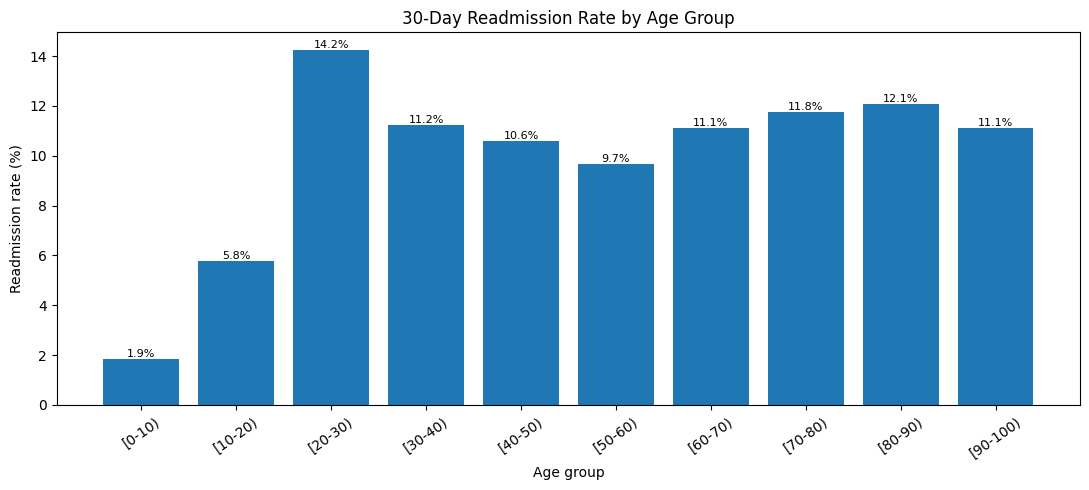

In [12]:
age_summary = (
    clean_df.groupBy("age")
    .agg(
        F.count("*").alias("total_encounters"),
        F.sum("readmitted_30_days").alias("readmitted_within_30_days")
    )
    .withColumn("readmission_rate_pct", F.round(100*F.col("readmitted_within_30_days")/F.col("total_encounters"), 2))
)
age_order = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
age_pd = age_summary.toPandas()
age_pd["age"] = pd.Categorical(age_pd["age"], categories=age_order, ordered=True)
age_pd = age_pd.sort_values("age")
display(age_pd)

plt.figure(figsize=(11, 5))
bars = plt.bar(age_pd["age"].astype(str), age_pd["readmission_rate_pct"])
plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age group")
plt.ylabel("Readmission rate (%)")
plt.xticks(rotation=35)
for b in bars:
    plt.text(b.get_x()+b.get_width()/2, b.get_height(), f"{b.get_height():.1f}%", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

,medical_specialty,total_encounters,readmitted_within_30_days,readmission_rate_pct
0,Oncology,348,66.0,18.97
1,Nephrology,1613,248.0,15.38
2,PhysicalMedicineandRehabilitation,391,60.0,15.35
3,Surgery-Vascular,533,74.0,13.88
4,Psychiatry,854,104.0,12.18
5,Family/GeneralPractice,7440,883.0,11.87
6,None,49949,5781.0,11.57
7,InternalMedicine,14635,1646.0,11.25
8,Emergency/Trauma,7565,846.0,11.18
9,Surgery-General,3099,342.0,11.04


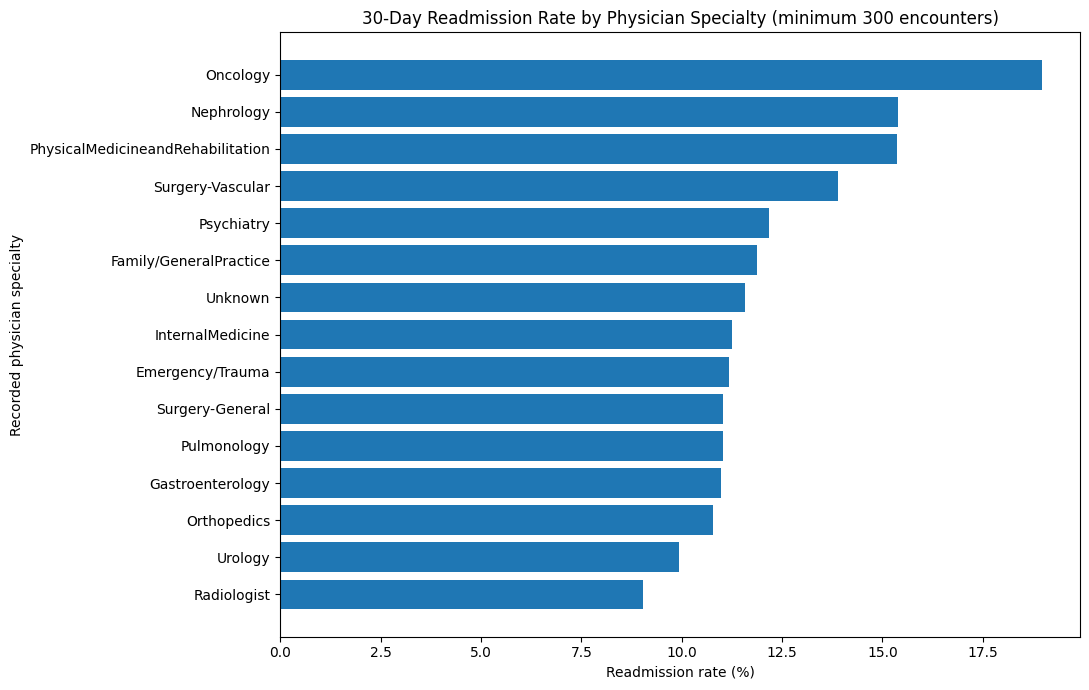

In [13]:
# Physician specialty is used as a proxy for department because the dataset does not provide a clean department field.
specialty_summary = (
    clean_df.groupBy("medical_specialty")
    .agg(F.count("*").alias("total_encounters"),
         F.sum("readmitted_30_days").alias("readmitted_within_30_days"))
    .withColumn("readmission_rate_pct", F.round(100*F.col("readmitted_within_30_days")/F.col("total_encounters"), 2))
    .filter(F.col("total_encounters") >= 300)
    .orderBy(F.desc("readmission_rate_pct"))
)
specialty_pd = specialty_summary.limit(15).toPandas()
display(specialty_pd)

plt.figure(figsize=(11, 7))
specialty_plot = specialty_pd.sort_values("readmission_rate_pct")
plt.barh(specialty_plot["medical_specialty"].fillna("Unknown"), specialty_plot["readmission_rate_pct"])
plt.title("30-Day Readmission Rate by Physician Specialty (minimum 300 encounters)")
plt.xlabel("Readmission rate (%)")
plt.ylabel("Recorded physician specialty")
plt.tight_layout()
plt.show()

,diagnosis_group,total_encounters,readmitted_within_30_days,readmission_rate_pct
0,Other/Non-numeric or unknown,1666,271.0,16.27
1,Blood disorders,1103,148.0,13.42
2,Diabetes,8757,1137.0,12.98
3,Injury/Poisoning,6974,854.0,12.25
4,Mental disorders,2262,276.0,12.20
5,Endocrine/Metabolic,2702,328.0,12.14
6,Circulatory,30336,3474.0,11.45
7,Infectious diseases,2768,317.0,11.45
8,Genitourinary,5078,549.0,10.81
9,Respiratory,10407,1112.0,10.69


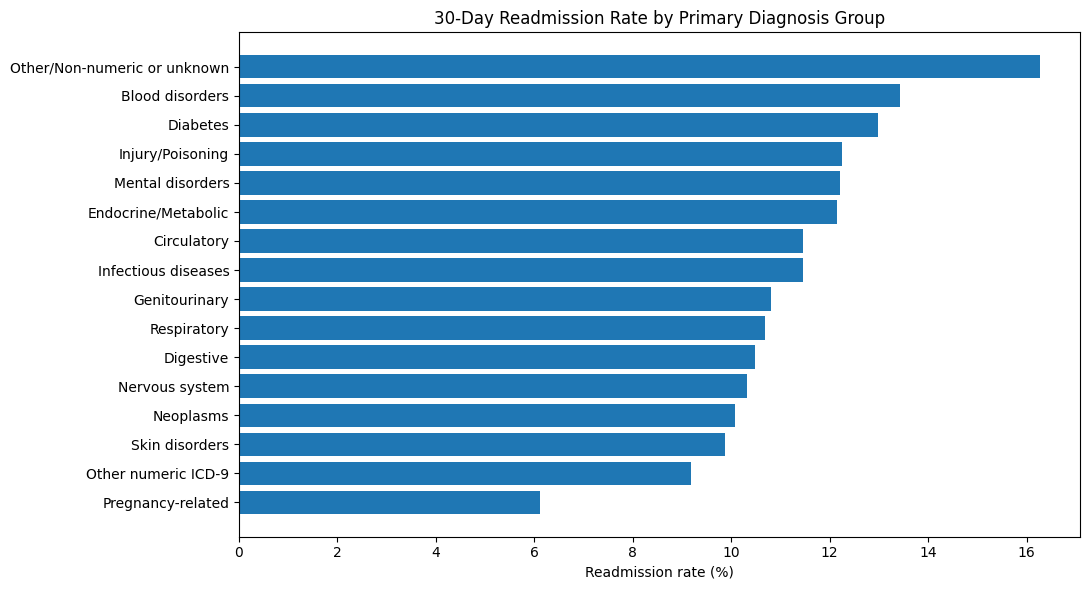

In [14]:
# Group primary diagnoses into broad ICD-9 ranges for an interpretable summary.
diag = clean_df.withColumn("diag1_text", F.trim(F.col("diag_1")))
diag = diag.withColumn("diag1_num", F.expr("try_cast(NULLIF(regexp_extract(diag1_text, '^(\\\\d+)', 1), '') AS INT)"))
diag = diag.withColumn(
    "diagnosis_group",
    F.when(F.col("diag1_num") == 250, "Diabetes")
     .when(F.col("diag1_num").between(390,459), "Circulatory")
     .when(F.col("diag1_num").between(460,519), "Respiratory")
     .when(F.col("diag1_num").between(520,579), "Digestive")
     .when(F.col("diag1_num").between(800,999), "Injury/Poisoning")
     .when(F.col("diag1_num").between(580,629), "Genitourinary")
     .when(F.col("diag1_num").between(140,239), "Neoplasms")
     .when(F.col("diag1_num").between(240,279), "Endocrine/Metabolic")
     .when(F.col("diag1_num").between(280,289), "Blood disorders")
     .when(F.col("diag1_num").between(290,319), "Mental disorders")
     .when(F.col("diag1_num").between(320,389), "Nervous system")
     .when(F.col("diag1_num").between(680,709), "Skin disorders")
     .when(F.col("diag1_num").between(1,139), "Infectious diseases")
     .when(F.col("diag1_num").between(630,679), "Pregnancy-related")
     .when(F.col("diag1_num").isNotNull(), "Other numeric ICD-9")
     .otherwise("Other/Non-numeric or unknown")
)
diagnosis_summary = (
    diag.groupBy("diagnosis_group")
    .agg(F.count("*").alias("total_encounters"),
         F.sum("readmitted_30_days").alias("readmitted_within_30_days"))
    .withColumn("readmission_rate_pct", F.round(100*F.col("readmitted_within_30_days")/F.col("total_encounters"), 2))
    .filter(F.col("total_encounters") >= 100)
    .orderBy(F.desc("readmission_rate_pct"))
)
diagnosis_pd = diagnosis_summary.toPandas()
display(diagnosis_pd)

plt.figure(figsize=(11, 6))
diagnosis_plot = diagnosis_pd.sort_values("readmission_rate_pct")
plt.barh(diagnosis_plot["diagnosis_group"], diagnosis_plot["readmission_rate_pct"])
plt.title("30-Day Readmission Rate by Primary Diagnosis Group")
plt.xlabel("Readmission rate (%)")
plt.tight_layout()
plt.show()

## 7. Prepare features carefully

The three fields `admission_type_id`, `discharge_disposition_id`, and `admission_source_id` are coded categories, not continuous measurements, so they are handled as categorical features.

Numeric measurement/count fields are explicitly cast to double. Categorical missing values become `"Unknown"`. The ID columns are excluded from predictors to reduce direct identifier leakage.

### Preparing columns for the model

We separate numerical and categorical columns. Numerical columns contain values such as number of medicines; categorical columns contain labels such as gender or medical specialty. IDs and the answer column are excluded from the predictors.

In [15]:
excluded_cols = [
    "encounter_id", "patient_nbr", "readmitted", "readmitted_30_days",
    "weight", "diag1_text", "diag1_num", "diagnosis_group"
]

numeric_cols = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]

all_predictor_cols = []
for column_name in clean_df.columns:
    if column_name not in excluded_cols:
        all_predictor_cols.append(column_name)

categorical_cols = []
for column_name in all_predictor_cols:
    if column_name not in numeric_cols:
        categorical_cols.append(column_name)

coded_categorical_cols = [
    "admission_type_id", "discharge_disposition_id", "admission_source_id"
]

model_df = clean_df.select(
    *[
        F.col(column_name).cast("double").alias(column_name)
        if column_name in numeric_cols
        else F.coalesce(
            F.col(column_name).cast("string"), F.lit("Unknown")
        ).alias(column_name)
        for column_name in numeric_cols + categorical_cols
    ],
    F.col("readmitted_30_days").cast("double").alias("label")
)

for column_name in numeric_cols:
    model_df = model_df.withColumn(
        column_name,
        F.when(F.isnan(F.col(column_name)), None).otherwise(F.col(column_name))
    )

print("Numeric predictors:", numeric_cols)
print("Categorical predictor count:", len(categorical_cols))
print("Coded categorical IDs:", coded_categorical_cols)
print("Model rows:", model_df.count())

Numeric predictors: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical predictor count: 38
Coded categorical IDs: ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
Model rows: 101766


## 8. Train/validation/test split and leakage-safe preprocessing




In [16]:
train_all, test_df = model_df.randomSplit([0.8, 0.2], seed=42)
fit_df, val_df = train_all.randomSplit([0.8, 0.2], seed=123)
print("Fit rows:", fit_df.count())
print("Validation rows:", val_df.count())
print("Test rows:", test_df.count())

Fit rows: 65104
Validation rows: 16287
Test rows: 20375


### Converting data into a format the model can use

The Decision Tree needs one feature vector. The Imputer fills missing numbers, StringIndexer converts text categories to numbers, OneHotEncoder represents categories safely, and VectorAssembler combines everything into one features column. Class weights help the model pay more attention to the smaller readmission group.

In [17]:
imputer = Imputer(
    inputCols=numeric_cols,
    outputCols=[c + "_imputed" for c in numeric_cols],
    strategy="median"
)
indexers = [
    StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep")
    for c in categorical_cols
]
encoder = OneHotEncoder(
    inputCols=[c+"_idx" for c in categorical_cols],
    outputCols=[c+"_ohe" for c in categorical_cols],
    handleInvalid="keep"
)
assembler_inputs = [c+"_imputed" for c in numeric_cols] + [c+"_ohe" for c in categorical_cols]
assembler = VectorAssembler(inputCols=assembler_inputs, outputCol="features", handleInvalid="keep")
# Handle imbalance with per-row weights for the Decision Tree.
class_counts = {r["label"]: r["count"] for r in fit_df.groupBy("label").count().collect()}
majority = max(class_counts.values())
minority = min(class_counts.values())
positive_weight = majority / max(minority, 1)
fit_weighted = fit_df.withColumn("class_weight", F.when(F.col("label") == 1.0, F.lit(float(positive_weight))).otherwise(F.lit(1.0)))
print("Training class counts:", class_counts)
print("Positive class weight:", round(positive_weight, 3))

Training class counts: {1.0: 7251, 0.0: 57853}
Positive class weight: 7.979


In [35]:
# 1. Evaluator on probability (ensures proper ROC-AUC calculation)
evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="probability",
    metricName="areaUnderROC"
)
dt = DecisionTreeClassifier(
    labelCol="label",
    featuresCol="features",
    weightCol="class_weight",
    maxBins=64,
    seed=42
)
cv_pipeline = Pipeline(stages=[imputer] + indexers + [encoder, assembler, dt])
paramGrid = (ParamGridBuilder()
             .addGrid(dt.maxDepth, [4, 6, 8])
             .build())

#5-Fold Cross-Validator
cv = CrossValidator(
    estimator=cv_pipeline,
    estimatorParamMaps=paramGrid,
    evaluator=evaluator,
    numFolds=5,
    seed=42
)

#Fit and print results
print("Running 5-Fold Cross-Validation...")
cv_model = cv.fit(fit_weighted)

print("\n5-Fold Cross-Validation Results")
print("-------------------------------")
print(f"Max Depth 4: ROC-AUC = {cv_model.avgMetrics[0]:.4f}")
print(f"Max Depth 6: ROC-AUC = {cv_model.avgMetrics[1]:.4f}")
print(f"Max Depth 8: ROC-AUC = {cv_model.avgMetrics[2]:.4f}")
print(f"\nBest Max Depth: {[4, 6, 8][cv_model.avgMetrics.index(max(cv_model.avgMetrics))]}")
print(f"Best Cross-Validation ROC-AUC: {max(cv_model.avgMetrics):.4f}")
print("\n5-Fold Cross-Validation Completed Successfully!")
print("Best Decision Tree model selected.")
dt_model = cv_model.bestModel

Running 5-Fold Cross-Validation...

5-Fold Cross-Validation Results
-------------------------------
Max Depth 4: ROC-AUC = 0.6440
Max Depth 6: ROC-AUC = 0.6517
Max Depth 8: ROC-AUC = 0.6484

Best Max Depth: 6
Best Cross-Validation ROC-AUC: 0.6517

5-Fold Cross-Validation Completed Successfully!
Best Decision Tree model selected.


## 9. Tune the decision threshold on validation data

Spark's default threshold is 0.5, which can miss many positive cases in an imbalanced dataset. We select a threshold on the validation set using F1, then evaluate that fixed threshold on the held-out test set. The test set is not used to choose the threshold.

### Choosing a classification threshold

The model produces a probability. We test the same thresholds from 0.05 to 0.50 and choose the threshold with the best validation F1 score (using recall as the tie-breaker).

,threshold,precision,recall,f1
0,0.05,0.116113,0.996245,0.207986
1,0.10,0.116113,0.996245,0.207986
2,0.15,0.116113,0.996245,0.207986
3,0.20,0.116113,0.996245,0.207986
4,0.25,0.120050,0.971030,0.213683
5,0.30,0.119843,0.967811,0.213277
6,0.35,0.129246,0.898069,0.225972
7,0.40,0.137335,0.848176,0.236394
8,0.45,0.167006,0.616953,0.262857
9,0.50,0.166788,0.613734,0.262295


Selected validation threshold: 0.45


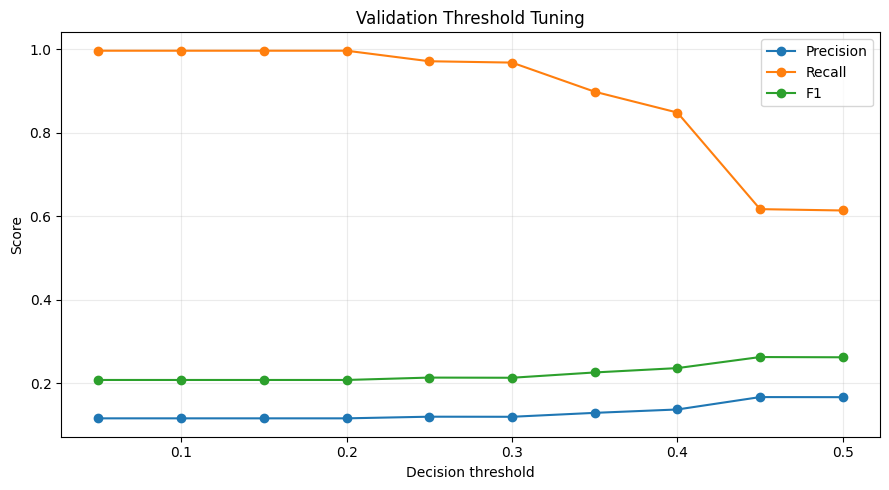

In [36]:
def add_positive_probability(pred_df):
    return pred_df.withColumn("prob_readmit", vector_to_array(F.col("probability"))[1])

val_pred = add_positive_probability(dt_model.transform(val_df))
threshold_rows = []
for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    temp = val_pred.withColumn("threshold_prediction", (F.col("prob_readmit") >= F.lit(threshold)).cast("double"))
    counts = temp.agg(
        F.sum(F.when((F.col("label")==1)&(F.col("threshold_prediction")==1),1).otherwise(0)).alias("tp"),
        F.sum(F.when((F.col("label")==0)&(F.col("threshold_prediction")==1),1).otherwise(0)).alias("fp"),
        F.sum(F.when((F.col("label")==1)&(F.col("threshold_prediction")==0),1).otherwise(0)).alias("fn")
    ).first()
    tp, fp, fn = [int(counts[k] or 0) for k in ["tp","fp","fn"]]
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    threshold_rows.append((threshold, precision, recall, f1))
threshold_pd = pd.DataFrame(threshold_rows, columns=["threshold","precision","recall","f1"])
display(threshold_pd)
best_threshold = float(threshold_pd.sort_values(["f1","recall"], ascending=False).iloc[0]["threshold"])
print("Selected validation threshold:", best_threshold)

plt.figure(figsize=(9,5))
plt.plot(threshold_pd["threshold"], threshold_pd["precision"], marker="o", label="Precision")
plt.plot(threshold_pd["threshold"], threshold_pd["recall"], marker="o", label="Recall")
plt.plot(threshold_pd["threshold"], threshold_pd["f1"], marker="o", label="F1")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Tuning")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Final test evaluation

Metrics below are calculated on the held-out test set. ROC-AUC uses the model's probability vector, not the hard class prediction. Accuracy is reported but should not be the only model-selection criterion.

In [37]:
test_pred = add_positive_probability(dt_model.transform(test_df))
test_pred = test_pred.withColumn("tuned_prediction", (F.col("prob_readmit") >= F.lit(best_threshold)).cast("double"))

def binary_counts(pred, prediction_col):
    row = pred.agg(
        F.sum(F.when((F.col("label")==1)&(F.col(prediction_col)==1),1).otherwise(0)).alias("tp"),
        F.sum(F.when((F.col("label")==0)&(F.col(prediction_col)==1),1).otherwise(0)).alias("fp"),
        F.sum(F.when((F.col("label")==1)&(F.col(prediction_col)==0),1).otherwise(0)).alias("fn"),
        F.sum(F.when((F.col("label")==0)&(F.col(prediction_col)==0),1).otherwise(0)).alias("tn")
    ).first()
    return {k:int(row[k] or 0) for k in ["tp","fp","fn","tn"]}

counts = binary_counts(test_pred, "tuned_prediction")
tp, fp, fn, tn = counts["tp"], counts["fp"], counts["fn"], counts["tn"]
accuracy = (tp+tn)/(tp+tn+fp+fn) if tp+tn+fp+fn else 0
precision = tp/(tp+fp) if tp+fp else 0
recall = tp/(tp+fn) if tp+fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0

auc_eval = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="probability",
    metricName="areaUnderROC"
)
roc_auc = auc_eval.evaluate(test_pred)

metrics_pd = pd.DataFrame([{
    "Model":"Weighted PySpark Decision Tree",
    "Threshold":best_threshold,
    "Accuracy":accuracy,
    "Precision_positive":precision,
    "Recall_positive":recall,
    "F1_positive":f1,
    "ROC_AUC":roc_auc,
    "TP":tp,"FP":fp,"FN":fn,"TN":tn
}])
display(metrics_pd)
print("Confusion counts:", counts)

,Model,Threshold,Accuracy,Precision_positive,Recall_positive,F1_positive,ROC_AUC,TP,FP,FN,TN
0,Weighted PySpark Decision Tree,0.45,0.605693,0.164892,0.635593,0.261852,0.654001,1425,7217,817,10916


Confusion counts: {'tp': 1425, 'fp': 7217, 'fn': 817, 'tn': 10916}


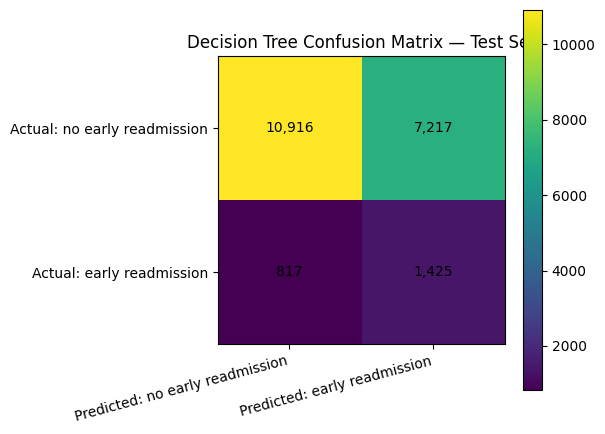

In [38]:
# Confusion matrix plotted from actual final test counts
cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(cm)
ax.set_xticks([0,1], labels=["Predicted: no early readmission","Predicted: early readmission"], rotation=15, ha="right")
ax.set_yticks([0,1], labels=["Actual: no early readmission","Actual: early readmission"])
ax.set_title("Decision Tree Confusion Matrix — Test Set")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i,j]:,}", ha="center", va="center")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

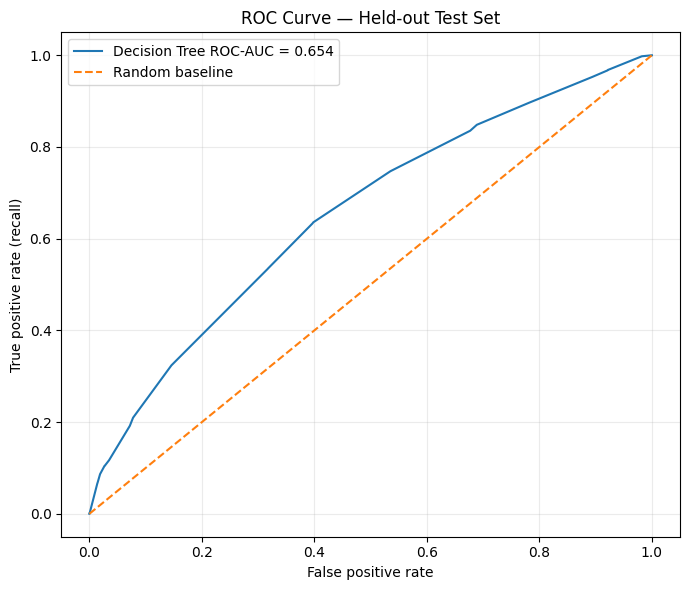

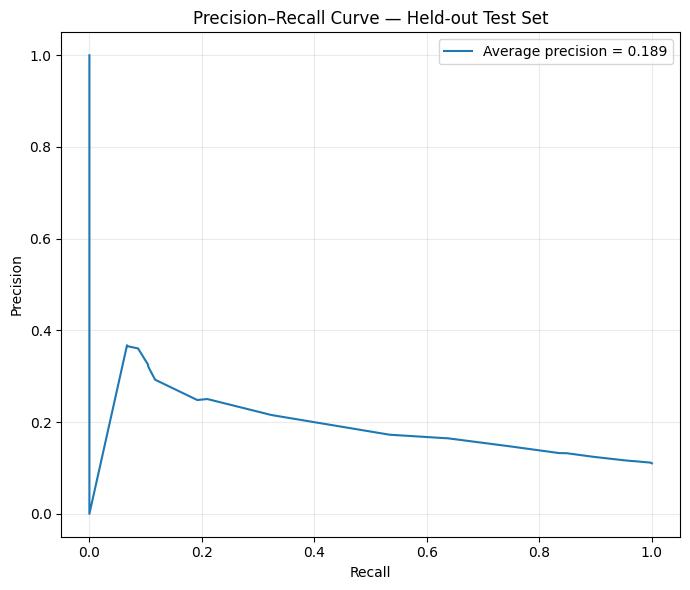

ROC-AUC recomputed from probability: 0.654
Average precision (PR-AUC summary): 0.1895


In [39]:
# ROC curve from Spark's scored test predictions.
# Collect only the small (label, probability) columns needed for plotting.
roc_pd = test_pred.select("label", "prob_readmit").toPandas()
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
fpr, tpr, _ = roc_curve(roc_pd["label"], roc_pd["prob_readmit"])
auc_from_prob = roc_auc_score(roc_pd["label"], roc_pd["prob_readmit"])

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"Decision Tree ROC-AUC = {auc_from_prob:.3f}")
plt.plot([0,1], [0,1], linestyle="--", label="Random baseline")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC Curve — Held-out Test Set")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

prec_curve, rec_curve, _ = precision_recall_curve(roc_pd["label"], roc_pd["prob_readmit"])
ap = average_precision_score(roc_pd["label"], roc_pd["prob_readmit"])
plt.figure(figsize=(7,6))
plt.plot(rec_curve, prec_curve, label=f"Average precision = {ap:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Held-out Test Set")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("ROC-AUC recomputed from probability:", round(float(auc_from_prob), 4))
print("Average precision (PR-AUC summary):", round(float(ap), 4))

## 11. Optional benchmark: PySpark Random Forest

This is an optional comparison model. It uses the same feature pipeline and split. Its output is not automatically “better”; compare recall, precision, F1 and ROC-AUC as well as accuracy. If runtime is tight, skip this section and keep the Decision Tree as the required model.

### Comparing with Random Forest

This final section trains the comparison model using the same prepared features and training data, then compares its test results with the Decision Tree.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Weighted Decision Tree (tuned threshold),0.605693,0.164892,0.635593,0.261852,0.654001
1,Weighted Random Forest (default threshold),0.617178,0.166467,0.618644,0.262342,0.658278


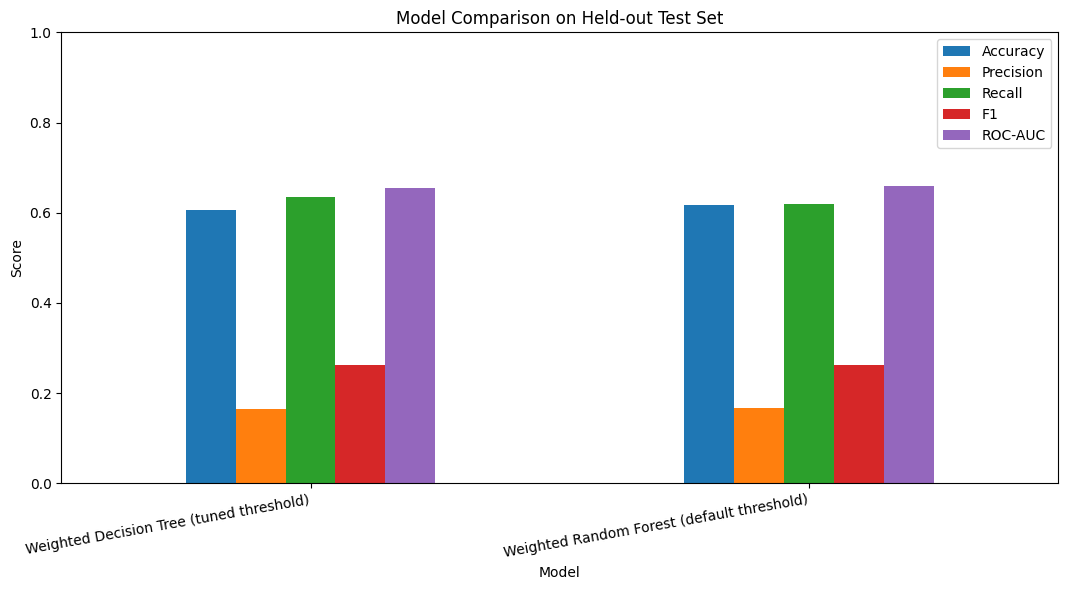

In [40]:
# Reuse the preprocessing stages but replace the classifier.
rf = RandomForestClassifier(
    labelCol="label", featuresCol="features", weightCol="class_weight",
    numTrees=40, maxDepth=8, seed=42
)
rf_pipeline = Pipeline(stages=[imputer] + indexers + [encoder, assembler, rf])
rf_model = rf_pipeline.fit(fit_weighted)
rf_test_pred = add_positive_probability(rf_model.transform(test_df))
rf_auc = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="probability",
    metricName="areaUnderROC"
).evaluate(rf_test_pred)

rf_test_default = rf_test_pred.withColumn("predicted_class", F.col("prediction").cast("double"))
rf_counts = binary_counts(rf_test_default, "predicted_class")
rf_tp, rf_fp, rf_fn, rf_tn = rf_counts["tp"], rf_counts["fp"], rf_counts["fn"], rf_counts["tn"]
rf_acc = (rf_tp+rf_tn)/(rf_tp+rf_tn+rf_fp+rf_fn)
rf_prec = rf_tp/(rf_tp+rf_fp) if rf_tp+rf_fp else 0
rf_rec = rf_tp/(rf_tp+rf_fn) if rf_tp+rf_fn else 0
rf_f1 = 2*rf_prec*rf_rec/(rf_prec+rf_rec) if rf_prec+rf_rec else 0

comparison_pd = pd.DataFrame([
    {"Model":"Weighted Decision Tree (tuned threshold)", "Accuracy":accuracy, "Precision":precision, "Recall":recall, "F1":f1, "ROC-AUC":roc_auc},
    {"Model":"Weighted Random Forest (default threshold)", "Accuracy":rf_acc, "Precision":rf_prec, "Recall":rf_rec, "F1":rf_f1, "ROC-AUC":rf_auc}
])
display(comparison_pd)

comparison_pd.set_index("Model")[["Accuracy","Precision","Recall","F1","ROC-AUC"]].plot(kind="bar", figsize=(11,6))
plt.title("Model Comparison on Held-out Test Set")
plt.ylabel("Score")
plt.xticks(rotation=10, ha="right")
plt.ylim(0,1)
plt.tight_layout()
plt.show()